In [14]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from tqdm import tqdm
from utils import SimpleDatasetMaker, ratemap_collage
import scipy
import matplotlib.patches as patches

In [2]:
# Optimization model
class OptimizationModel:
    def __init__(self, d = 256):
        k = 1/torch.sqrt(torch.tensor(d, dtype=torch.float32))
        self.A = (k*torch.rand((d, d))).requires_grad_()
        self.B = (k*torch.rand((d, d))).requires_grad_()
        self.d = d
        self.optimizer = torch.optim.Adam([self.A, self.B], lr=0.001)

    def objective_function(self, p0, pt, dr):
        # Compute e^(A + B)
        C = torch.matrix_exp(dr[...,0, None, None]*self.A[None] + dr[...,1,None,None]*self.B[None])
        p_pred = torch.bmm(C, p0[...,None]).squeeze()
        # require commutation
        commutation_loss = torch.mean((self.A@self.B - self.B@self.A)**2)
        return torch.mean((pt - p_pred)**2) + commutation_loss

    def optimize(self, n, ratemaps, bs = 33):
        self.loss_history = []

        for _ in tqdm(range(n)):
            self.optimizer.zero_grad()  # Clear previous gradients
            # starting pixels
            i0 = torch.randint(0, ratemaps.shape[0]-1, size = (bs, 2))
            # pixel step
            di = torch.randint(-2, 2, size = (bs, 2))
            # check if in bounds
            i_trial = i0 + di
            mask = torch.abs(i_trial - (ratemaps.shape[0]-1)/2) > ((ratemaps.shape[0]-1)/2)
            di = -di*mask + di*(~mask)
            it = i0 + di # valid step

            # it = torch.randint(0, ratemaps.shape[0]-1, size = (bs, 2))
            di = it - i0
            dr = (2/ratemaps.shape[0])*di.float()

            loss = self.objective_function(ratemaps[i0[:,0], i0[:,1]], ratemaps[it[:,0], it[:,1]], dr)  # Compute the loss
            loss.backward()  # Backpropagation
            self.optimizer.step()  # Update parameters
            self.loss_history.append(loss.item())
        return self.loss_history


torch.Size([32, 32, 102])

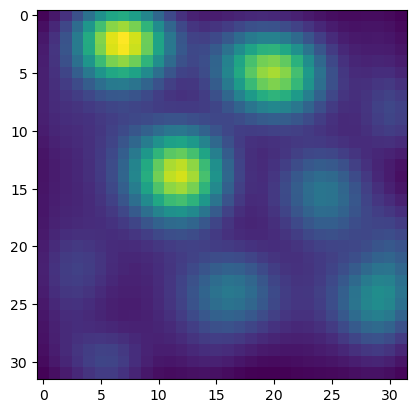

In [3]:
# load data
original_ratemaps = np.load("gc_ratmaps.npy").astype("float32")
original_ratemaps = np.transpose(original_ratemaps, (1,2,0))
plt.imshow(original_ratemaps[...,0])

ratemaps = torch.tensor(original_ratemaps)
ratemaps.shape

In [4]:
model = OptimizationModel(d = ratemaps.shape[-1])

In [5]:
loss_history = model.optimize(20000, ratemaps)

100%|██████████| 20000/20000 [10:39<00:00, 31.29it/s]


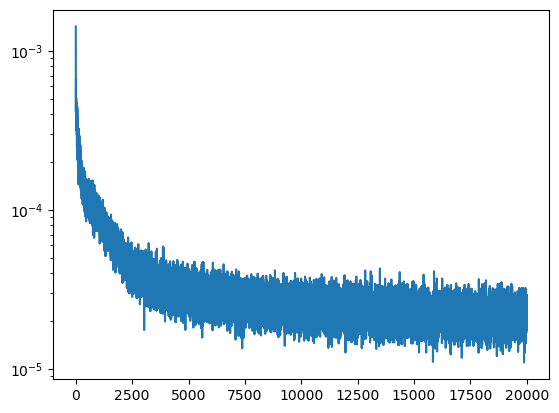

In [6]:
plt.semilogy(model.loss_history)

In [7]:
genny = SimpleDatasetMaker(rayleigh_scale=0.1, chamber_size=2) # trajectory dataset generator

steps = 10000
r, v = genny.generate_dataset(100, steps)
ind = torch.argmin(torch.linalg.norm(r[:,0], axis=  -1)) # center!
r = r[ind]
v = v[ind]
r = r.squeeze()
v = v.squeeze()
# shift to center to compare with ratemaps
r = r - r[0,None]

(-2.290500968694687, 2.107923239469528, -2.1147850692272185, 2.282357209920883)

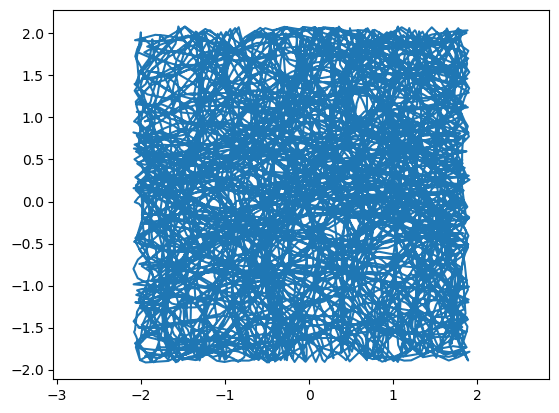

In [8]:
plt.plot(r[:,0], r[:,1])
plt.axis("equal")

In [9]:
# only generation 
p_prime = torch.full((ratemaps.shape[-1], steps), torch.nan, dtype = torch.float32)
p_prime[:,0] = ratemaps[ratemaps.shape[0]//2,ratemaps.shape[1]//2] # start in center

for i in range(steps-1):
    z = p_prime[:,i]
    dr = v[i]
    theta = np.arctan2(dr[1], dr[0])
    m = torch.sqrt(dr[0]**2 + dr[1]**2)
    C = dr[0]*model.A + dr[1]*model.B
    Q = torch.matrix_exp(C)
    p_prime[:,i+1] = Q@z

p_prime = p_prime.detach().numpy()

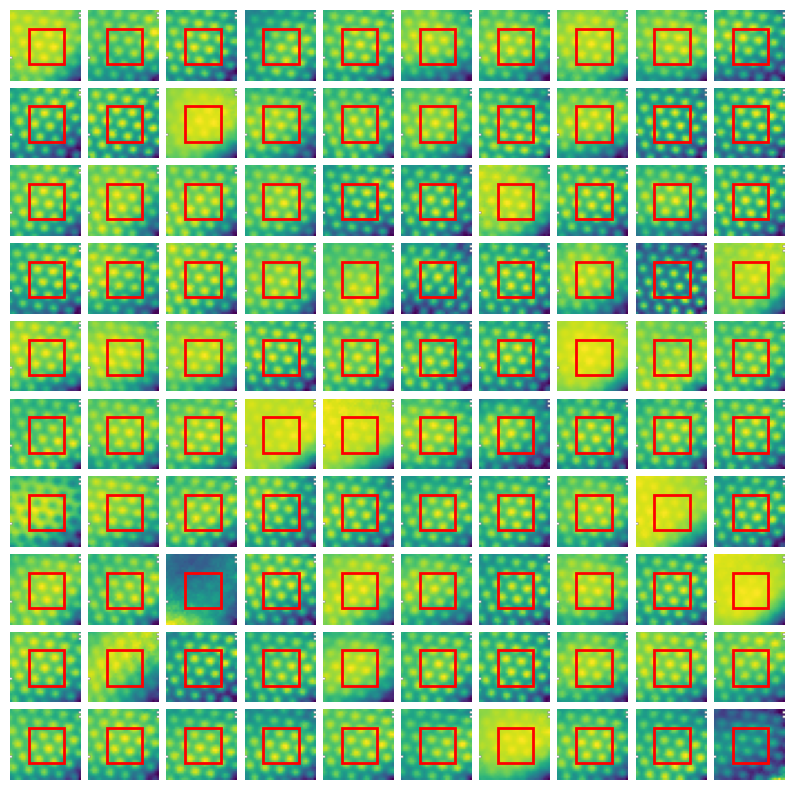

In [ ]:
from matplotlib.pylab import size


bins = original_ratemaps.shape[0]
model_ratemaps = scipy.stats.binned_statistic_2d(r[:,0], r[:,1], p_prime, bins = 32)[0]

# 32 = 1 
s = 32/2
fig, axs = ratemap_collage(model_ratemaps[:100],10, 10, figsize = (10, 10))
for ax in axs.flatten():
    square = patches.Rectangle((16- s/2, 16-s/2),s, s, edgecolor='red',facecolor='none',linewidth=2)
    ax.add_patch(square)
    ax.set_xticks([])
    ax.set_yticks([])

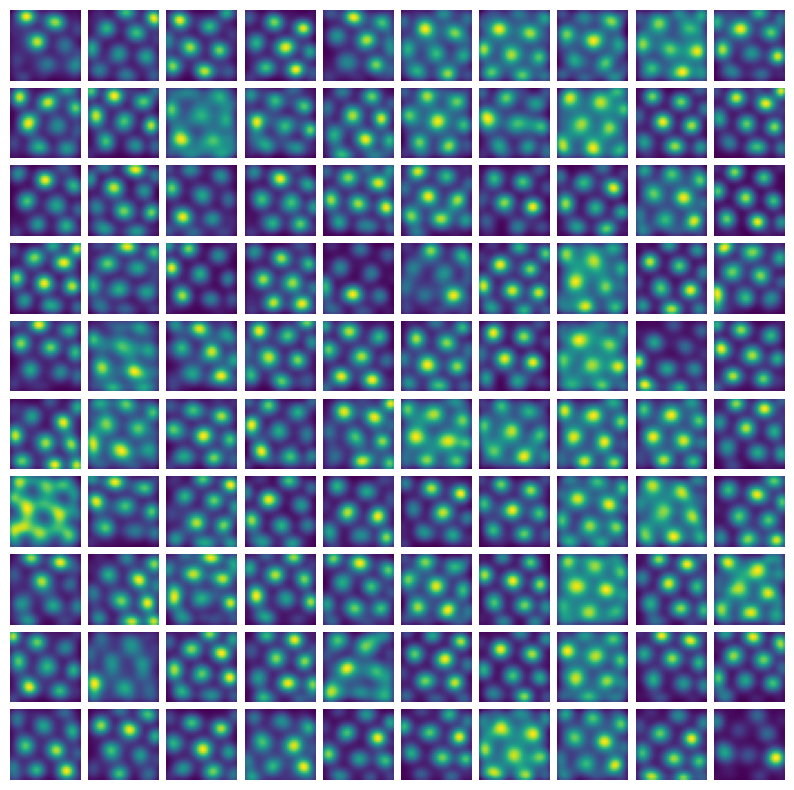

In [11]:
ratemap_collage(original_ratemaps.transpose(2, 0, 1)[:100], 10, 10, figsize = (10,10));

Text(0.5, 1.0, 'Learned Norm')

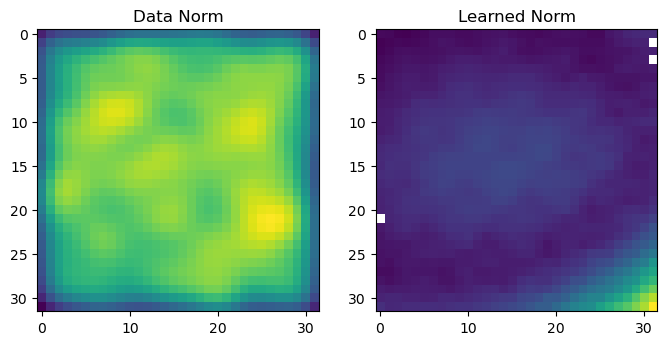

In [12]:
fig, ax = plt.subplots(1, 2, figsize = (8, 4))
ax[0].imshow(np.linalg.norm(ratemaps, axis = -1))
ax[1].imshow(np.linalg.norm(model_ratemaps, axis = 0))
ax[0].set_title("Data Norm")
ax[1].set_title("Learned Norm")

NameError: name 'pp_prime' is not defined

<Figure size 500x500 with 0 Axes>

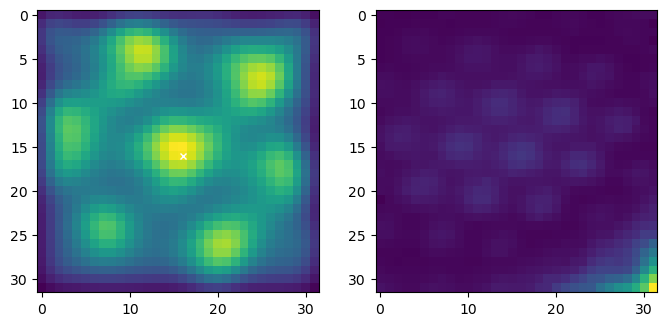

In [13]:
plt.figure(figsize = (5,5))
a = original_ratemaps.shape[0]//2 
b = original_ratemaps.shape[1]//2 

dp_data = np.nansum((original_ratemaps*original_ratemaps[a,b,None,None])**2,axis=-1)
dp_learned = np.nansum((model_ratemaps*model_ratemaps[:,model_ratemaps.shape[-1]//2,model_ratemaps.shape[-1]//2,None,None])**2,axis=0)

fig, ax = plt.subplots(1, 2, figsize = (8, 4))
ax[0].imshow(dp_data)
ax[1].imshow(dp_learned)
ax[0].plot(b,a, "wx", markersize = 5)
ax[1].plot(pp_prime.shape[-1]//2,pp_prime.shape[-1]//2, "wx", markersize = 5)
ax[0].set_title("Data")
ax[1].set_title("Learned")

In [ ]:
A_eigs = np.linalg.eigvals(model.A.detach().numpy())
B_eigs = np.linalg.eigvals(model.B.detach().numpy())

Text(0, 0.5, 'Im')

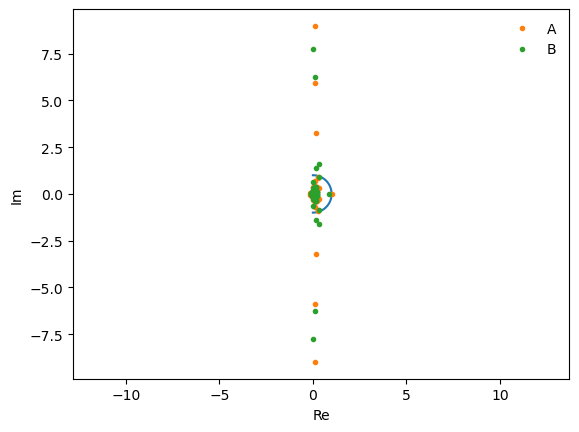

In [ ]:
theta = np.linspace(-np.pi/2, np.pi/2, 100)
plt.plot(np.cos(theta), np.sin(theta))

plt.plot(A_eigs.real, A_eigs.imag, ".", label = "A")
plt.plot(B_eigs.real, B_eigs.imag, ".", label = "B")
plt.legend(frameon = False)
plt.axis("equal")
plt.xlabel("Re")
plt.ylabel("Im")

(-0.18510967195034028,
 1.05649935901165,
 -0.14050255604088308,
 0.8865914110094308)

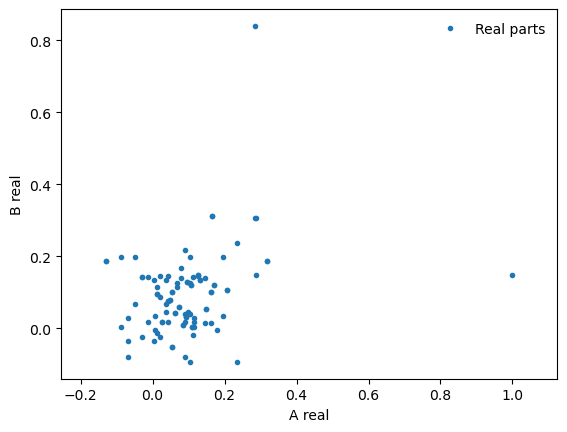

In [ ]:
plt.plot(A_eigs.real, B_eigs.real, ".", label = "Real parts")
plt.xlabel("A real")
plt.ylabel("B real")
plt.legend(frameon = False)
plt.axis("equal")

(-9.882497787475586, 9.882497787475586, -8.518282985687256, 8.518282985687256)

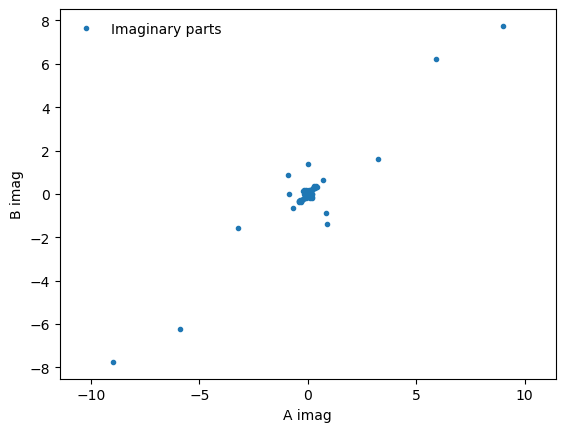

In [ ]:
plt.plot(A_eigs.imag, B_eigs.imag, ".", label = "Imaginary parts")
plt.xlabel("A imag")
plt.ylabel("B imag")
plt.legend(frameon = False)
plt.axis("equal")

(array([ 3.,  3., 13.,  1.,  2.,  1.,  4.,  2.,  0.,  3.,  7.,  3.,  4.,
         0.,  0.,  6.,  1.,  2.,  3., 13.,  1.,  2.,  1.,  3.,  2.,  2.,
         1.,  6.,  6.,  2.,  1.,  4.]),
 array([-2.79405403, -2.60856509, -2.42307615, -2.23758721, -2.05209827,
        -1.86660922, -1.68112028, -1.49563134, -1.3101424 , -1.12465346,
        -0.93916452, -0.75367552, -0.56818658, -0.38269764, -0.19720867,
        -0.01171972,  0.17376924,  0.35925817,  0.54474711,  0.73023611,
         0.91572505,  1.10121405,  1.28670299,  1.47219193,  1.65768087,
         1.84316981,  2.02865887,  2.21414781,  2.39963675,  2.58512568,
         2.77061462,  2.95610356,  3.1415925 ]),
 <BarContainer object of 32 artists>)

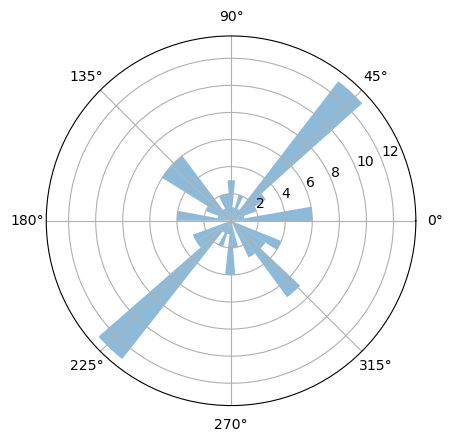

In [ ]:
phi = np.arctan2(A_eigs.imag, B_eigs.imag)
plt.subplot(projection = 'polar')
plt.hist(phi, alpha = 0.5, bins = 32)

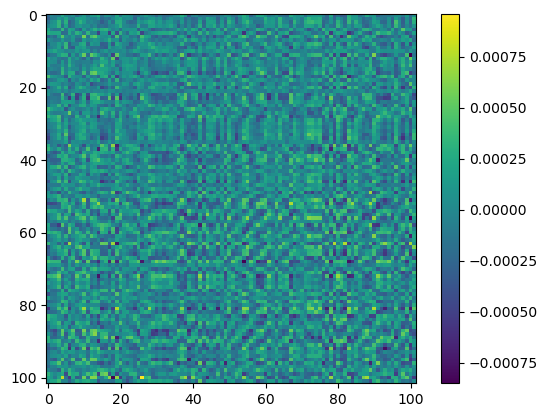

In [ ]:
commutator = model.A@model.B - model.B@model.A
plt.imshow(commutator.detach().numpy())
plt.colorbar()

(array([  3.,   1.,   0.,   1.,   1.,   1.,   2.,   4.,   5.,   5.,   5.,
          9.,  11.,  14.,  12.,  15.,  18.,  25.,  24.,  34.,  51.,  53.,
         58.,  60.,  63.,  73.,  91.,  91., 121., 141., 142., 161., 193.,
        225., 199., 211., 241., 240., 259., 272., 276., 297., 286., 288.,
        307., 308., 279., 277., 263., 274., 303., 259., 289., 292., 264.,
        272., 251., 255., 227., 209., 186., 194., 186., 185., 153., 134.,
        106., 110.,  82.,  83.,  51.,  44.,  55.,  40.,  33.,  33.,  28.,
         11.,  19.,  14.,   6.,   9.,   6.,   7.,   3.,   7.,   0.,   4.,
          2.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          1.]),
 array([-8.51906836e-04, -8.33774160e-04, -8.15641426e-04, -7.97508750e-04,
        -7.79376016e-04, -7.61243340e-04, -7.43110606e-04, -7.24977930e-04,
        -7.06845196e-04, -6.88712520e-04, -6.70579844e-04, -6.52447110e-04,
        -6.34314434e-04, -6.16181700e-04, -5.98049024e-04, -5.79916290e-04,
        -5.617

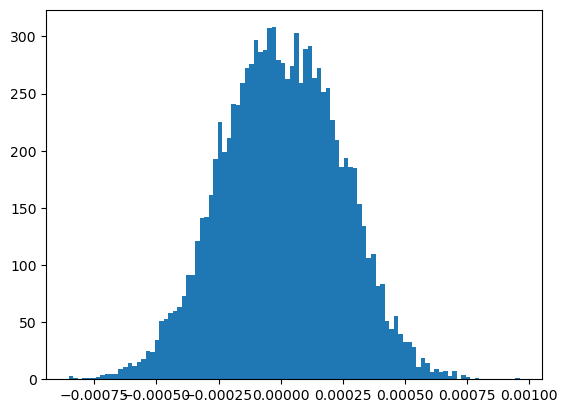

In [ ]:
plt.hist(commutator.detach().numpy().flatten(), bins = 100)